# Notebook 9: Categorical Data Analysis

## Dataset Setup

This notebook analyzes categorical features in the Online Retail II dataset.

The analysis covers unique categories, category frequencies, distribution, rare categories, cardinality, category imbalance, and relationships between categorical features and a suitable target variable.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "online_retail_II.xlsx"
df = pd.read_excel(file_path, sheet_name="Year 2009-2010")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# Topic 1: Unique Categories

## Step 1: Understand the Concept

Unique categories are the distinct values present in a categorical column.

For example, if a Country column contains India, France, India, and Germany, the unique categories are India, France, and Germany.

The number of unique categories is 3.

### Why Is It Important?

- Identifies the different categories in a feature.
- Helps understand the structure of categorical data.
- Detects unexpected or inconsistent category values.
- Helps determine whether a feature has low or high cardinality.
- Supports feature selection and preprocessing in machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following Country values:

| Row | Country |
|---|---|
| 1 | India |
| 2 | France |
| 3 | India |
| 4 | Germany |
| 5 | France |

The unique categories are India, France, and Germany. Therefore, the column contains 3 unique categories.

### Real-World Example

An online shopping platform may sell products to customers from several countries. Identifying unique countries helps understand the geographical coverage of the business.

### Business Example

A retail company can identify the different countries, product descriptions, and stock codes present in its sales data.

### AI/ML Use Case

Unique category analysis helps determine how categorical variables should be encoded before training a machine learning model.

### Important Characteristics

- Repeated values count as one unique category.
- Missing values should be examined separately.
- Inconsistent spelling can create unintended categories.
- A high number of unique categories may indicate high cardinality.

In [2]:

# Select important categorical columns
categorical_columns = ["Country", "Description", "StockCode"]

for column in categorical_columns:
    if column not in df.columns:
        print(f"\nColumn '{column}' is not available in the dataset.")
        continue

    # Count unique non-missing categories
    unique_count = df[column].nunique()

    # Get the unique category values
    unique_values = df[column].dropna().unique()

    print(f"\n{'=' * 45}")
    print(f"Column: {column}")
    print(f"Number of unique categories: {unique_count}")
    print(f"Number of missing values: {df[column].isna().sum()}")

    print("Sample unique categories:")
    print(unique_values[:10])



Column: Country
Number of unique categories: 40
Number of missing values: 0
Sample unique categories:
<ArrowStringArray>
['United Kingdom',         'France',            'USA',        'Belgium',
      'Australia',           'EIRE',        'Germany',       'Portugal',
          'Japan',        'Denmark']
Length: 10, dtype: str

Column: Description
Number of unique categories: 4681
Number of missing values: 2928
Sample unique categories:
['15CM CHRISTMAS GLASS BALL 20 LIGHTS' 'PINK CHERRY LIGHTS'
 ' WHITE CHERRY LIGHTS' 'RECORD FRAME 7" SINGLE SIZE '
 'STRAWBERRY CERAMIC TRINKET BOX' 'PINK DOUGHNUT TRINKET POT '
 'SAVE THE PLANET MUG' 'FANCY FONT HOME SWEET HOME DOORMAT' 'CAT BOWL '
 'DOG BOWL , CHASING BALL DESIGN']

Column: StockCode
Number of unique categories: 4632
Number of missing values: 0
Sample unique categories:
[85048 '79323P' '79323W' 22041 21232 22064 21871 21523 22350 22349]


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code examines the `Country`, `Description`, and `StockCode` columns.

For each column, it:
- Checks whether the column exists.
- Counts its unique non-missing values.
- Retrieves the distinct values.
- Displays up to 10 sample categories.
- Counts missing values separately.

### 2. Why These Methods Were Used

- **`nunique()`** counts distinct non-missing values by default.
- **`unique()`** returns the distinct values in the column.
- **`dropna()`** excludes missing values when displaying sample categories.
- **`isna().sum()`** counts missing values.
- **`df.columns`** helps check whether a column exists before analyzing it.

These Pandas methods make categorical inspection simple and efficient.

### 3. What the Output Means

- **Number of unique categories:** Shows how many distinct non-missing values a column contains.
- **Number of missing values:** Shows how many records do not have a value for that column.
- **Sample unique categories:** Provides examples of the different values present.

The exact counts depend on the dataset and will appear when the code runs.

### 4. Insights to Identify

After running the code, check:

- How many different countries are represented.
- Whether product descriptions contain many distinct values.
- Whether stock codes have a high number of unique values.
- Whether any categorical columns contain missing values.
- Whether category values appear inconsistent or duplicated because of spelling or formatting differences.

### 5. Impact on an ML Pipeline

- **Encoding:** Helps decide how categorical values can be converted into numerical features.
- **Cardinality:** Helps identify columns that may need special encoding strategies.
- **Data Cleaning:** Helps detect inconsistent category labels.
- **Feature Selection:** Helps evaluate whether a categorical column is useful for the prediction task.
- **Memory and Complexity:** Columns with many unique values may increase the size and complexity of encoded features.

### Conclusion

Unique category analysis provides an initial understanding of categorical columns. The results help guide further frequency analysis, cardinality assessment, and categorical feature preprocessing.

# Topic 2: Category Frequencies

## Step 1: Understand the Concept

Category frequency is the number of times a particular category appears in a categorical column.

For example, if a Country column contains:

- UK: 4 records
- France: 3 records
- Germany: 2 records

The frequency of UK is 4, France is 3, and Germany is 2.

### Why Is It Important?

- Identifies the most and least frequent categories.
- Helps understand customer and product patterns.
- Highlights categories that may require further investigation.
- Supports the detection of rare categories and category imbalance.
- Helps guide categorical feature preprocessing in machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Consider the following Country values:

| Country |
|---|
| UK |
| France |
| UK |
| Germany |
| UK |
| France |

The category frequencies are:

| Country | Frequency |
|---|---:|
| UK | 3 |
| France | 2 |
| Germany | 1 |

UK is the most frequent category in this example.

### Real-World Example

An online store can count orders or transaction records associated with each country to understand where its retail activity is concentrated.

### Business Example

A retail team can identify frequently appearing stock codes and product descriptions to understand which products occur most often in the transaction dataset.

### AI/ML Use Case

Category frequencies help identify dominant categories and rare categories before selecting encoding or preprocessing strategies.

### Important Characteristics

- Frequency represents the number of occurrences.
- Relative frequency represents the proportion of records in a category.
- Missing values are excluded by default when using `value_counts()`.
- High frequency does not automatically mean high revenue or high profit.

In [3]:

categorical_columns = ["Country", "Description", "StockCode"]

for column in categorical_columns:
    if column not in df.columns:
        print(f"\nColumn '{column}' is not available in the dataset.")
        continue

    # Count occurrences of each category
    frequency = df[column].value_counts()

    # Calculate percentage of non-missing records
    percentage = df[column].value_counts(normalize=True) * 100

    # Combine frequency and percentage
    frequency_table = pd.DataFrame({
        "Frequency": frequency,
        "Percentage (%)": percentage.round(2)
    })

    print(f"\n{'=' * 50}")
    print(f"Category Frequencies: {column}")
    print(f"{'=' * 50}")
    display(frequency_table.head(10))

    print("Total non-missing records:", df[column].count())
    print("Number of categories:", df[column].nunique())



Category Frequencies: Country


,Frequency,Percentage (%)
Country,,
United Kingdom,485852,92.46
EIRE,9670,1.84
Germany,8129,1.55
France,5772,1.10
Netherlands,2769,0.53
Spain,1278,0.24
Switzerland,1187,0.23
Portugal,1101,0.21
Belgium,1054,0.20


Total non-missing records: 525461
Number of categories: 40

Category Frequencies: Description


,Frequency,Percentage (%)
Description,,
WHITE HANGING HEART T-LIGHT HOLDER,3549,0.68
REGENCY CAKESTAND 3 TIER,2212,0.42
STRAWBERRY CERAMIC TRINKET BOX,1843,0.35
PACK OF 72 RETRO SPOT CAKE CASES,1466,0.28
ASSORTED COLOUR BIRD ORNAMENT,1457,0.28
60 TEATIME FAIRY CAKE CASES,1400,0.27
HOME BUILDING BLOCK WORD,1386,0.27
JUMBO BAG RED RETROSPOT,1310,0.25
LUNCH BAG RED SPOTTY,1274,0.24


Total non-missing records: 522533
Number of categories: 4681

Category Frequencies: StockCode


,Frequency,Percentage (%)
StockCode,,
85123A,3516,0.67
22423,2221,0.42
85099B,2057,0.39
21212,1933,0.37
21232,1843,0.35
20725,1620,0.31
84879,1458,0.28
84991,1400,0.27
21754,1386,0.26


Total non-missing records: 525461
Number of categories: 4632


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code analyzes category frequencies in `Country`, `Description`, and `StockCode`.

For each column, it:
- Counts how often each category appears.
- Calculates each category's percentage among non-missing values.
- Displays the 10 most frequent categories.
- Reports the total number of non-missing records and unique categories.

### 2. Why These Methods Were Used

- **`value_counts()`** counts the occurrences of each category and sorts them from highest to lowest frequency by default.
- **`value_counts(normalize=True)`** calculates the proportion of each category.
- **Multiplying by 100** converts proportions into percentages.
- **`pd.DataFrame()`** combines frequency and percentage into one table.
- **`count()`** returns the number of non-missing values.
- **`nunique()`** counts distinct non-missing categories.

### 3. What the Output Means

- **Frequency:** Number of records for a category.
- **Percentage (%):** Proportion of non-missing records represented by that category.
- **Top 10 categories:** The categories with the highest frequencies.
- **Total non-missing records:** Number of records included in the frequency calculation.

Percentages for each column are calculated using that column's non-missing records.

### 4. Insights to Identify

After running the code, examine:

- Which country appears most frequently.
- Which product descriptions and stock codes appear most often.
- Whether a small number of categories account for a large proportion of records.
- Whether some categories occur very rarely.
- Whether frequent categories should be investigated further using revenue or quantity metrics.

Remember that frequency alone does not indicate sales value, profitability, or customer demand.

### 5. Impact on an ML Pipeline

- **Rare Category Handling:** Helps identify categories that may need grouping or special treatment.
- **Encoding:** Supports choosing an appropriate categorical encoding method.
- **Class Imbalance Investigation:** Helps inspect category imbalance in categorical features. For a classification target, target-class frequencies should be analyzed separately.
- **Feature Engineering:** Can help identify useful frequency-based features when designed without data leakage.
- **Model Evaluation:** Reveals whether predictions might be dominated by frequently represented categories.

### Conclusion

Category frequency analysis identifies the most common and least common values in categorical columns. These results support category distribution analysis, rare-category detection, and further business investigation.

# Topic 3: Category Distribution

## Step 1: Understand the Concept

Category distribution describes how observations are spread across the different categories in a categorical feature.

It helps us understand whether records are distributed evenly across categories or concentrated in a few categories.

### Why Is It Important?

- Identifies dominant categories.
- Shows whether categories are evenly or unevenly distributed.
- Helps identify patterns in retail transactions.
- Supports rare-category and category-imbalance analysis.
- Helps data scientists understand categorical features before model training.

## Step 2: Demonstrate the Concept

### Simple Example

Consider a dataset containing 100 shopping transactions:

| Country | Number of Records | Percentage |
|---|---:|---:|
| UK | 70 | 70% |
| France | 20 | 20% |
| Germany | 10 | 10% |
| Total | 100 | 100% |

The distribution is uneven because the UK accounts for most of the records.

### Real-World Example

An online store may receive transactions from many countries, but most transactions may come from only a few countries.

### Business Example

A retail manager can examine category distributions to understand where transaction activity is concentrated and where additional investigation may be useful.

### AI/ML Use Case

Category distribution analysis helps identify features dominated by a few categories. For a classification target, it can also reveal class imbalance.

### Important Characteristics

- Frequency shows the number of occurrences.
- Percentage shows each category's share of the total.
- A bar chart makes comparisons easier.
- An uneven distribution does not automatically indicate a data-quality problem.


Category Distribution: Country


,Frequency,Percentage (%)
Country,,
United Kingdom,485852,92.46
EIRE,9670,1.84
Germany,8129,1.55
France,5772,1.10
Netherlands,2769,0.53
Spain,1278,0.24
Switzerland,1187,0.23
Portugal,1101,0.21
Belgium,1054,0.20


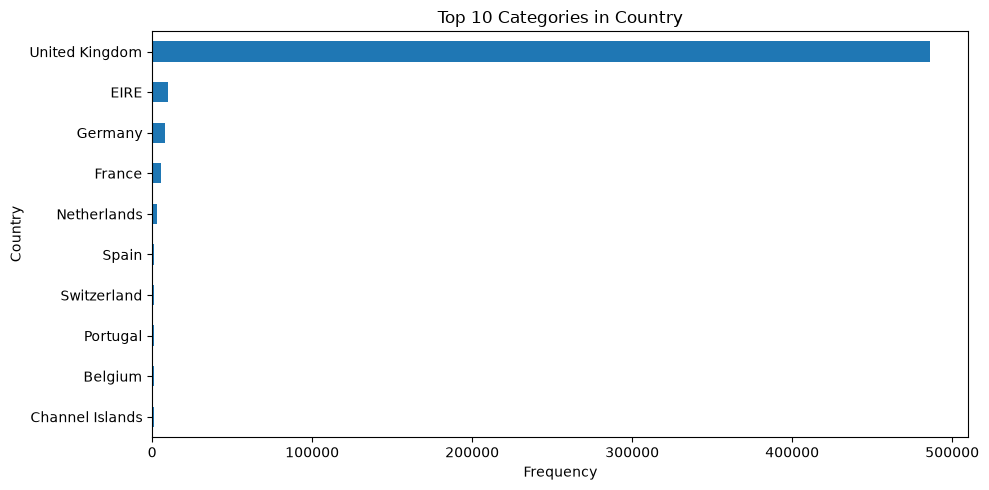


Category Distribution: Description


,Frequency,Percentage (%)
Description,,
WHITE HANGING HEART T-LIGHT HOLDER,3549,0.68
REGENCY CAKESTAND 3 TIER,2212,0.42
STRAWBERRY CERAMIC TRINKET BOX,1843,0.35
PACK OF 72 RETRO SPOT CAKE CASES,1466,0.28
ASSORTED COLOUR BIRD ORNAMENT,1457,0.28
60 TEATIME FAIRY CAKE CASES,1400,0.27
HOME BUILDING BLOCK WORD,1386,0.27
JUMBO BAG RED RETROSPOT,1310,0.25
LUNCH BAG RED SPOTTY,1274,0.24


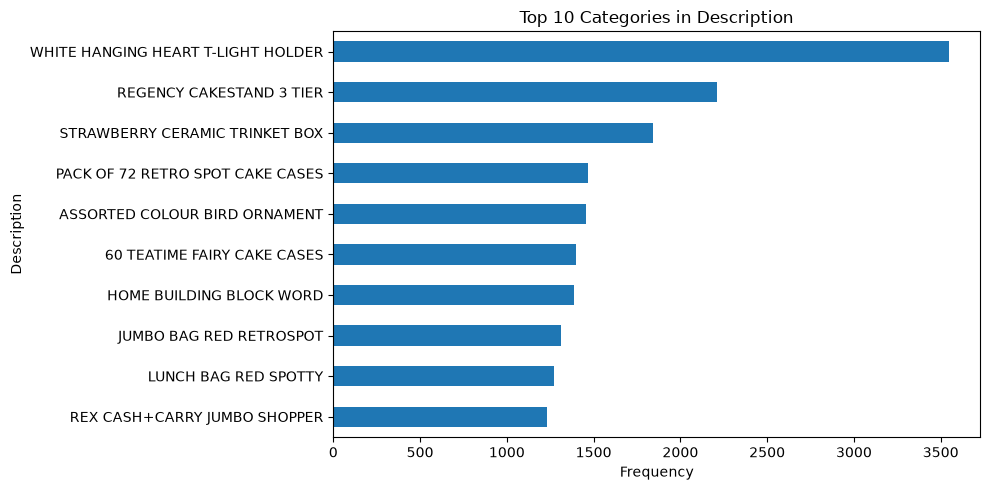


Category Distribution: StockCode


,Frequency,Percentage (%)
StockCode,,
85123A,3516,0.67
22423,2221,0.42
85099B,2057,0.39
21212,1933,0.37
21232,1843,0.35
20725,1620,0.31
84879,1458,0.28
84991,1400,0.27
21754,1386,0.26


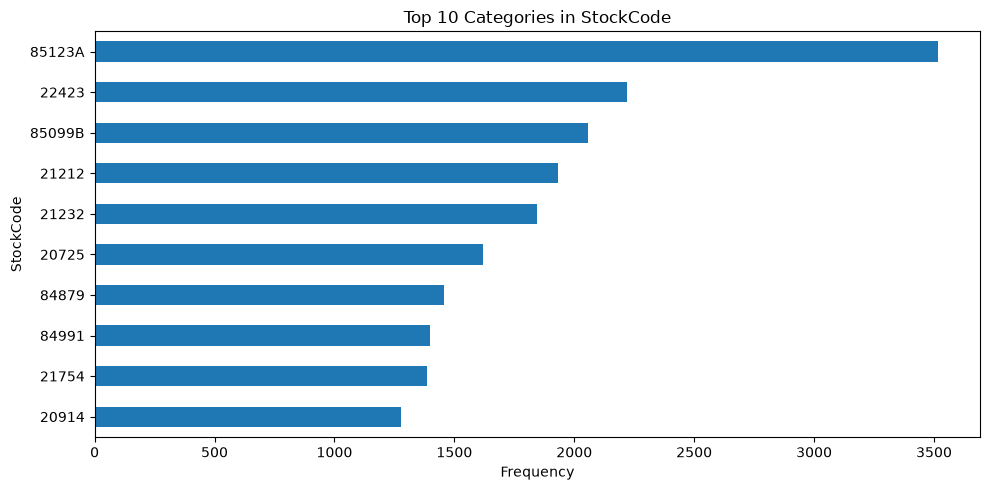

In [4]:

categorical_columns = ["Country", "Description", "StockCode"]

for column in categorical_columns:
    if column not in df.columns:
        print(f"\nColumn '{column}' is not available in the dataset.")
        continue

    # Calculate category percentages
    category_counts = df[column].value_counts()
    category_percentages = (
        df[column].value_counts(normalize=True) * 100
    )

    # Create a distribution table
    distribution_table = pd.DataFrame({
        "Frequency": category_counts,
        "Percentage (%)": category_percentages.round(2)
    })

    print(f"\nCategory Distribution: {column}")
    display(distribution_table.head(10))

    # Plot the top 10 categories
    plot_data = category_counts.head(10).sort_values()

    plt.figure(figsize=(10, 5))
    plot_data.plot(kind="barh")
    plt.title(f"Top 10 Categories in {column}")
    plt.xlabel("Frequency")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code analyzes the distribution of categories in `Country`, `Description`, and `StockCode`.

It:
- Counts the occurrences of each category.
- Calculates each category's percentage of non-missing values.
- Displays the 10 most frequent categories.
- Creates a horizontal bar chart for easy comparison.

### 2. Why These Methods Were Used

- **`value_counts()`** calculates the frequency of each category.
- **`value_counts(normalize=True)`** calculates category proportions.
- **Multiplying by 100** converts proportions into percentages.
- **`pd.DataFrame()`** organizes the results into a table.
- **`head(10)`** selects the 10 most frequent categories.
- **`sort_values()`** arranges the selected counts for clearer bar-chart presentation.
- **`plot(kind="barh")`** creates a horizontal bar chart that is useful for long category labels.

### 3. What the Output Means

- The table shows each category's frequency and percentage.
- Longer bars indicate categories with more records.
- A category with a large percentage represents a larger share of the non-missing observations.
- A few dominant bars may indicate that records are concentrated in a small number of categories.

The actual distribution must be interpreted from your output.

### 4. Insights to Identify

After running the code, check:

- Whether a few countries account for most transactions.
- Whether product descriptions have a concentrated or widely spread distribution.
- Whether stock codes occur at very different frequencies.
- Whether some categories have very small percentages.
- Whether the distribution raises questions for further business analysis.

Frequency represents transaction-record counts, not necessarily revenue or profit.

### 5. Impact on an ML Pipeline

- **Feature Encoding:** Helps determine whether categorical features need special encoding strategies.
- **Rare Category Handling:** Identifies categories that may require further investigation.
- **Class Imbalance:** Helps motivate a separate target-variable distribution check for classification problems.
- **Feature Engineering:** Category proportions can support useful features when computed without data leakage.
- **Model Interpretation:** Helps explain which categories dominate the available data.

### Conclusion

Category distribution analysis shows how observations are spread across categorical values. Frequency tables and bar charts make dominant categories and uneven distributions easier to identify.

# Topic 4: Rare Categories

## Step 1: Understand the Concept

Rare categories are categorical values that appear in only a small number or percentage of observations in a dataset.

For example, a retail dataset may contain thousands of records for one country but only a few records for another country.

The less frequent category may be considered rare, depending on the analysis objective.

### Why Is It Important?

- Identifies categories with very few observations.
- Helps detect unusual or uncommon business patterns.
- Supports decisions about categorical feature encoding.
- Helps reduce unnecessary complexity in some machine learning models.
- Helps investigate whether rare values are valid or caused by data-quality issues.

## Step 2: Demonstrate the Concept

### Simple Example

Consider these transaction counts:

| Country | Frequency |
|---|---:|
| UK | 800 |
| France | 120 |
| Germany | 70 |
| Country A | 3 |
| Country B | 2 |

Country A and Country B have very low frequencies compared with the other categories.

They may be considered rare categories for this example.

### Real-World Example

An online retailer may receive most orders from a few countries and only occasional orders from other countries.

### Business Example

A retail team can investigate whether categories with few transactions represent genuine business activity, unusual demand, or data-entry inconsistencies.

### AI/ML Use Case

Rare categories can create sparse features when one-hot encoding is used. Depending on the problem, they may be grouped into an "Other" category or handled with a different encoding method.

### Important Characteristics

- Rarity depends on frequency and the purpose of the analysis.
- A rare category is not necessarily incorrect.
- Grouping categories can remove useful information.
- Category grouping rules should be learned from training data when preparing a predictive model.

In [5]:

categorical_columns = ["Country", "Description", "StockCode"]

# Example threshold for identifying rare categories
rare_threshold = 10

for column in categorical_columns:
    if column not in df.columns:
        print(f"\nColumn '{column}' is not available in the dataset.")
        continue

    category_counts = df[column].value_counts()

    # Categories appearing 10 times or fewer
    rare_categories = category_counts[
        category_counts <= rare_threshold
    ]

    print(f"\n{'=' * 50}")
    print(f"Rare Category Analysis: {column}")
    print(f"{'=' * 50}")
    print(f"Total unique categories: {df[column].nunique()}")
    print(f"Rare category count: {len(rare_categories)}")
    print(f"Records in rare categories: {rare_categories.sum()}")

    print(f"\nSample rare categories (up to 10):")
    display(rare_categories.head(10).to_frame("Frequency"))

    # Percentage of non-missing records belonging to rare categories
    total_non_missing = df[column].count()

    if total_non_missing > 0:
        rare_percentage = (
            rare_categories.sum() / total_non_missing
        ) * 100
        print(
            f"Percentage of records in rare categories: "
            f"{rare_percentage:.2f}%"
        )



Rare Category Analysis: Country
Total unique categories: 40
Rare category count: 0
Records in rare categories: 0

Sample rare categories (up to 10):


,Frequency
Country,


Percentage of records in rare categories: 0.00%

Rare Category Analysis: Description
Total unique categories: 4681
Rare category count: 1068
Records in rare categories: 4528

Sample rare categories (up to 10):


,Frequency
Description,
VINTAGE ROSE BEAD BRACELET BLUE,10
PINK GINGHAM ROSE CUSHION COVER,10
ICON PLACEMAT POP ART ELVIS,10
SCOTTS ROSES TILE COASTER,10
FAIRY CAKES WALL THERMOMETER,10
GLASS BEAD HOOP EARRINGS AMETHYST,10
IVORY SHELL HEART EARRINGS,10
BLUE STAR BLOCK TABLE LAMP,10
VINTAGE PINK TINSEL REEL,10


Percentage of records in rare categories: 0.87%

Rare Category Analysis: StockCode
Total unique categories: 4632
Rare category count: 1195
Records in rare categories: 4479

Sample rare categories (up to 10):


,Frequency
StockCode,
20825,10
84706F,10
21266,10
20887,10
72024U,10
90033,10
21595,10
84705A,10
20988,10


Percentage of records in rare categories: 0.85%


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code analyzes rare categories in `Country`, `Description`, and `StockCode`.

It:
- Counts the frequency of every category.
- Identifies categories that appear 10 times or fewer.
- Counts how many categories meet the rare-category rule.
- Calculates the total records belonging to those categories.
- Displays up to 10 examples and their frequencies.
- Calculates the percentage of non-missing records that belong to rare categories.

### 2. Why These Methods Were Used

- **`value_counts()`** counts occurrences of each category.
- **Boolean filtering** selects categories meeting the threshold.
- **`len()`** counts the number of categories identified as rare.
- **`sum()`** adds their frequencies to calculate how many records they represent.
- **`count()`** provides the non-missing record count used as the percentage denominator.
- **`to_frame()`** presents the selected frequencies in a readable table.

### 3. What the Output Means

- **Rare category count:** Number of distinct categories occurring 10 times or fewer.
- **Records in rare categories:** Total observations belonging to those categories.
- **Sample rare categories:** Examples of low-frequency values.
- **Percentage of records in rare categories:** Share of non-missing observations belonging to those categories.

The actual counts will depend on the dataset.

### 4. Insights to Identify

After running the code, examine:

- Whether many categories have very low frequencies.
- Whether rare categories account for only a small percentage of all records.
- Whether rare countries or products represent valid business activity.
- Whether some values require spelling or data-quality checks.
- Whether category grouping would be useful for a particular analysis.

### 5. Impact on an ML Pipeline

- **One-Hot Encoding:** Rare categories may create features with very few non-zero values.
- **Category Grouping:** Rare values can sometimes be grouped into "Other" if this makes business and modelling sense.
- **Generalization:** Models may struggle to learn reliable patterns from categories with very few examples.
- **Data Quality:** Rare values can be reviewed for inconsistencies without assuming they are errors.
- **Data Leakage Prevention:** For predictive modelling, learn rare-category grouping rules from training data and apply the same rules to validation and test data.

### Conclusion

Rare category analysis identifies infrequent categorical values and measures how many records they represent. The results help decide whether categories need further investigation or special handling.

The threshold of 10 is an example for this notebook. It should be adjusted based on dataset size and business requirements. Rare categories should not be removed or grouped automatically.

# Topic 5: High Cardinality

## Step 1: Understand the Concept

High cardinality refers to a categorical feature that contains a large number of distinct categories.

For example, a retail dataset may contain thousands of unique stock codes or product descriptions.

### Why Is It Important?

- Identifies categorical features with many distinct values.
- Helps select appropriate encoding techniques.
- Highlights features that may increase model complexity.
- Helps manage memory usage and the size of encoded datasets.
- Supports feature engineering and preprocessing decisions in machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Consider two categorical columns:

| Customer Type | Stock Code |
|---|---|
| Regular | S1001 |
| New | S1002 |
| Regular | S1003 |
| New | S1004 |
| Regular | S1005 |

The Customer Type column has only two unique categories, while Stock Code has five unique values in this small example.

In a real retail dataset, stock codes may have thousands of distinct values.

### Real-World Example

An e-commerce platform may have a large product catalogue, with a different stock code for each product.

### Business Example

A retailer can identify high-cardinality columns to understand the complexity of product-level and customer-level data.

### AI/ML Use Case

High-cardinality features may create a very large number of columns when one-hot encoding is used. Alternatives include frequency encoding, carefully designed target encoding, hashing, or suitable embedding methods.

### Important Characteristics

- High cardinality means many unique categories relative to the dataset and task.
- There is no universal threshold that defines high cardinality.
- A high-cardinality feature is not automatically unhelpful.
- Encoding choices should consider model type, data size, and business meaning.

In [6]:

categorical_columns = ["Country", "Description", "StockCode", "Invoice", "Customer ID"]

high_cardinality_threshold = 0.50

cardinality_results = []

for column in categorical_columns:
    if column not in df.columns:
        print(f"Column '{column}' is not available in the dataset.")
        continue

    non_missing_count = df[column].count()
    unique_count = df[column].nunique()

    if non_missing_count > 0:
        cardinality_ratio = unique_count / non_missing_count
    else:
        cardinality_ratio = np.nan

    cardinality_results.append({
        "Column": column,
        "Unique Categories": unique_count,
        "Non-Missing Records": non_missing_count,
        "Cardinality Ratio": cardinality_ratio,
        "High Cardinality Candidate": (
            cardinality_ratio > high_cardinality_threshold
            if pd.notna(cardinality_ratio)
            else False
        )
    })

cardinality_df = pd.DataFrame(cardinality_results)

print("Categorical Feature Cardinality Analysis")
display(cardinality_df.sort_values(
    by="Unique Categories", ascending=False
).reset_index(drop=True))


Categorical Feature Cardinality Analysis


,Column,Unique Categories,Non-Missing Records,Cardinality Ratio,High Cardinality Candidate
0,Invoice,28816,525461,0.054839,False
1,Description,4681,522533,0.008958,False
2,StockCode,4632,525461,0.008815,False
3,Customer ID,4383,417534,0.010497,False
4,Country,40,525461,0.000076,False


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code examines selected columns: `Country`, `Description`, `StockCode`, `Invoice`, and `Customer ID`.

It:
- Counts unique categories.
- Counts non-missing records.
- Calculates the ratio of unique categories to non-missing records.
- Flags columns whose ratio exceeds the example threshold of 0.50.
- Displays the results in descending order of unique category count.

Although some columns are identifiers rather than ordinary categorical features, they are included to inspect their cardinality.

### 2. Why These Methods Were Used

- **`nunique()`** counts distinct non-missing values.
- **`count()`** counts non-missing observations.
- **Cardinality ratio** helps compare unique-value counts with the number of available records.
- **`pd.notna()`** checks that the ratio is valid before classification.
- **`pd.DataFrame()`** organizes the results into a comparison table.
- **`sort_values()`** puts columns with more unique values first.

### 3. What the Output Means

- **Unique Categories:** Number of distinct non-missing values.
- **Non-Missing Records:** Number of observations available for comparison.
- **Cardinality Ratio:** Unique category count divided by non-missing record count.
- **High Cardinality Candidate:** Whether the ratio exceeds the chosen example threshold.

A high ratio is only an initial signal. A column with many unique values may still be useful, and the ratio alone does not determine the best encoding method.

### 4. Insights to Identify

After running the code, check:

- Which columns contain the most unique values.
- Whether `StockCode` and `Description` have high cardinality.
- Whether `Invoice` or `Customer ID` behave more like identifiers.
- Whether a high-cardinality feature is useful for the intended business question.
- Whether the chosen threshold is suitable for the dataset.

### 5. Impact on an ML Pipeline

- **One-Hot Encoding:** High-cardinality columns can create many additional features.
- **Alternative Encoding:** Frequency encoding, hashing, or carefully implemented target encoding may be appropriate in some tasks.
- **Identifier Handling:** Invoice numbers and customer IDs should not automatically be used as predictive features; evaluate their meaning and leakage risk.
- **Memory Usage:** Large encoded matrices may require more memory.
- **Generalization:** Very specific categories may not provide enough observations for reliable learning.

### Conclusion

High-cardinality analysis identifies categorical columns with many distinct values and helps guide preprocessing decisions. Cardinality must be interpreted alongside business meaning, sample size, and the modelling objective.

# Topic 6: Low Cardinality

## Step 1: Understand the Concept

Low cardinality refers to a categorical feature that contains a relatively small number of distinct categories.

For example, a feature such as Payment Method might contain only Cash, Card, and Online Payment.

### Why Is It Important?

- Identifies features with a small number of categories.
- Helps select simple categorical encoding methods.
- Makes category comparisons easier.
- Helps understand the structure of categorical data.
- Supports feature preprocessing for machine learning models.

## Step 2: Demonstrate the Concept

### Simple Example

Consider a column called Membership Type:

| Membership Type |
|---|
| Basic |
| Premium |
| Basic |
| Standard |
| Premium |

The unique categories are Basic, Premium, and Standard. Therefore, the column has 3 unique categories.

### Real-World Example

An online shopping platform may classify orders into a small number of payment methods or delivery types.

### Business Example

A retail manager can compare sales records across a small set of categories to understand differences in transaction activity.

### AI/ML Use Case

Low-cardinality categorical features are often suitable for one-hot encoding. Ordinal encoding may be appropriate when categories have a meaningful order.

### Important Characteristics

- Contains relatively few distinct categories.
- Often easy to summarize using frequency tables and bar charts.
- Usually creates fewer encoded features than high-cardinality columns.
- The best encoding method depends on whether the categories have a meaningful order and on the model being used.

In [7]:

categorical_columns = ["Country", "Description", "StockCode", "Invoice", "Customer ID"]

# Example threshold: at most 10 unique non-missing values
low_cardinality_threshold = 10

results = []

for column in categorical_columns:
    if column not in df.columns:
        print(f"Column '{column}' is not available in the dataset.")
        continue

    unique_count = df[column].nunique()
    non_missing_count = df[column].count()

    results.append({
        "Column": column,
        "Unique Categories": unique_count,
        "Non-Missing Records": non_missing_count,
        "Low Cardinality Candidate": (
            unique_count <= low_cardinality_threshold
        )
    })

low_cardinality_df = pd.DataFrame(results)

print("Low Cardinality Analysis")
display(
    low_cardinality_df.sort_values(
        by="Unique Categories", ascending=True
    ).reset_index(drop=True)
)

# Display unique values for columns identified as low-cardinality candidates
for _, row in low_cardinality_df.iterrows():
    column = row["Column"]

    if row["Low Cardinality Candidate"]:
        print(f"\nUnique values in {column}:")
        print(df[column].dropna().unique())


Low Cardinality Analysis


,Column,Unique Categories,Non-Missing Records,Low Cardinality Candidate
0,Country,40,525461,False
1,Customer ID,4383,417534,False
2,StockCode,4632,525461,False
3,Description,4681,522533,False
4,Invoice,28816,525461,False


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code examines selected dataset columns and counts their unique non-missing values.

It:
- Counts unique values for each column.
- Records the number of non-missing observations.
- Flags columns with 10 or fewer unique values.
- Sorts the results by unique category count.
- Displays distinct values for columns flagged as low-cardinality candidates.

### 2. Why These Methods Were Used

- **`nunique()`** counts unique non-missing values.
- **`count()`** counts non-missing observations.
- **Boolean comparison** checks whether the unique count meets the selected threshold.
- **`pd.DataFrame()`** organizes the results into a table.
- **`sort_values()`** places columns with fewer unique values first.
- **`dropna().unique()`** displays distinct non-missing values.

### 3. What the Output Means

- **Unique Categories:** Number of distinct values in the column.
- **Non-Missing Records:** Number of available observations.
- **Low Cardinality Candidate:** Indicates whether the column has 10 or fewer unique values.
- **Unique Values:** Shows the distinct values in columns meeting the threshold.

The threshold of 10 is an example for this notebook, not a universal definition of low cardinality.

### 4. Insights to Identify

After running the code, examine:

- Which columns contain only a few distinct values.
- Whether any column is suitable for a simple frequency table.
- Whether a column contains unexpected category values.
- Whether an identifier or text field has more categories than expected.
- Whether the selected threshold is appropriate for the dataset and analysis goal.

### 5. Impact on an ML Pipeline

- **One-Hot Encoding:** Often works well for low-cardinality nominal features.
- **Ordinal Encoding:** Can be useful when categories have a genuine order.
- **Interpretability:** A small number of categories makes feature effects easier to inspect.
- **Data Cleaning:** Unexpected values can reveal inconsistent labels.
- **Feature Selection:** Cardinality helps guide preprocessing, but it does not by itself establish whether a feature is useful.

### Conclusion

Low-cardinality analysis identifies columns with relatively few distinct values. It helps simplify categorical data inspection and supports the selection of suitable encoding strategies.

Always consider the meaning of each feature before encoding it.

# Topic 7: Category Imbalance

## Step 1: Understand the Concept

Category imbalance occurs when observations are distributed unevenly across the categories of a categorical feature or target variable.

For example, a dataset may contain many records from one country but very few records from other countries.

### Why Is It Important?

- Identifies dominant and underrepresented categories.
- Helps explain patterns in categorical data.
- Supports investigation of rare categories.
- Helps identify class imbalance in classification problems.
- Supports better model evaluation and preprocessing decisions.

## Step 2: Demonstrate the Concept

### Simple Example

Consider a dataset containing 100 customer records:

| Customer Type | Frequency | Percentage |
|---|---:|---:|
| Regular | 90 | 90% |
| New | 10 | 10% |

The distribution is imbalanced because Regular customers account for most of the records.

### Real-World Example

An online retailer may receive most transactions from one country, while several other countries contribute only a small number of records.

### Business Example

A business analyst can investigate whether transaction activity is concentrated in particular countries or product categories.

### AI/ML Use Case

When a classification target has highly unequal class frequencies, a model may perform well on the majority class but poorly on the minority class.

### Important Characteristics

- Imbalance describes unequal representation.
- Imbalance in an input feature is not the same as target-class imbalance.
- An imbalanced distribution is not automatically a data-quality problem.
- Classification problems may require metrics such as precision, recall, F1-score, and a confusion matrix.


Category Imbalance Analysis: Country
Total non-missing records: 525461
Number of unique categories: 40

Top 10 categories:


,Frequency,Percentage (%)
Country,,
United Kingdom,485852,92.46
EIRE,9670,1.84
Germany,8129,1.55
France,5772,1.10
Netherlands,2769,0.53
Spain,1278,0.24
Switzerland,1187,0.23
Portugal,1101,0.21
Belgium,1054,0.20



Bottom 10 categories:


,Frequency,Percentage (%)
Country,,
Lebanon,13,0.00
Nigeria,32,0.01
Bermuda,34,0.01
West Indies,54,0.01
Brazil,62,0.01
Korea,63,0.01
Iceland,71,0.01
Israel,74,0.01
Thailand,76,0.01


Most frequent category count: 485852
Least frequent category count: 13
Most-to-least frequency ratio: 37373.23


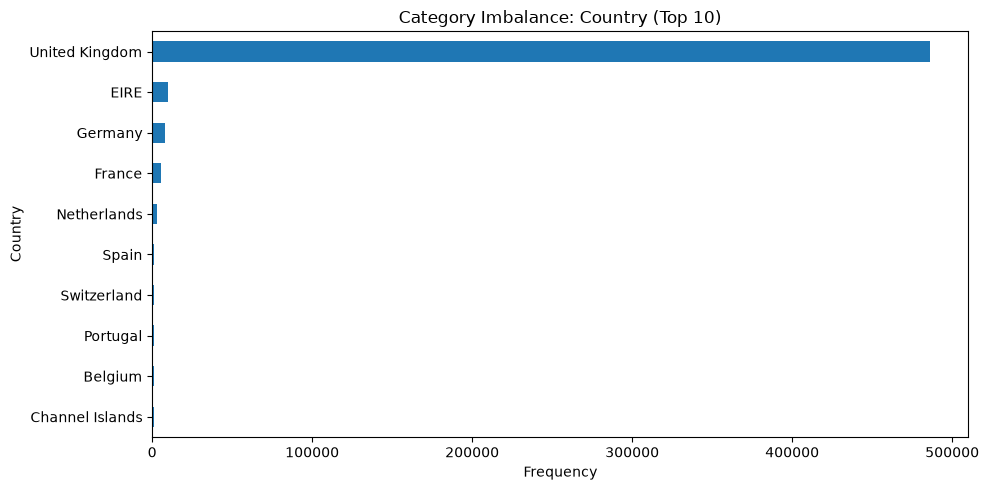


Category Imbalance Analysis: Description
Total non-missing records: 522533
Number of unique categories: 4681

Top 10 categories:


,Frequency,Percentage (%)
Description,,
WHITE HANGING HEART T-LIGHT HOLDER,3549,0.68
REGENCY CAKESTAND 3 TIER,2212,0.42
STRAWBERRY CERAMIC TRINKET BOX,1843,0.35
PACK OF 72 RETRO SPOT CAKE CASES,1466,0.28
ASSORTED COLOUR BIRD ORNAMENT,1457,0.28
60 TEATIME FAIRY CAKE CASES,1400,0.27
HOME BUILDING BLOCK WORD,1386,0.27
JUMBO BAG RED RETROSPOT,1310,0.25
LUNCH BAG RED SPOTTY,1274,0.24



Bottom 10 categories:


,Frequency,Percentage (%)
Description,,
PALE PINK/AMETHYST STONE NECKLACE,1,0.0
MOP PENDANT SHELL NECKLACE,1,0.0
mailout addition,1,0.0
AMBER 3 BEAD DROP EARRINGS,1,0.0
GLASS BELL JAR SMALL,1,0.0
GLASS BELL JAR LARGE,1,0.0
"SILICON CUBE 25W, BLUE",1,0.0
BAKING MOULD EASTER EGG MILK CHOC,1,0.0
*Boombox Ipod Classic,1,0.0


Most frequent category count: 3549
Least frequent category count: 1
Most-to-least frequency ratio: 3549.0


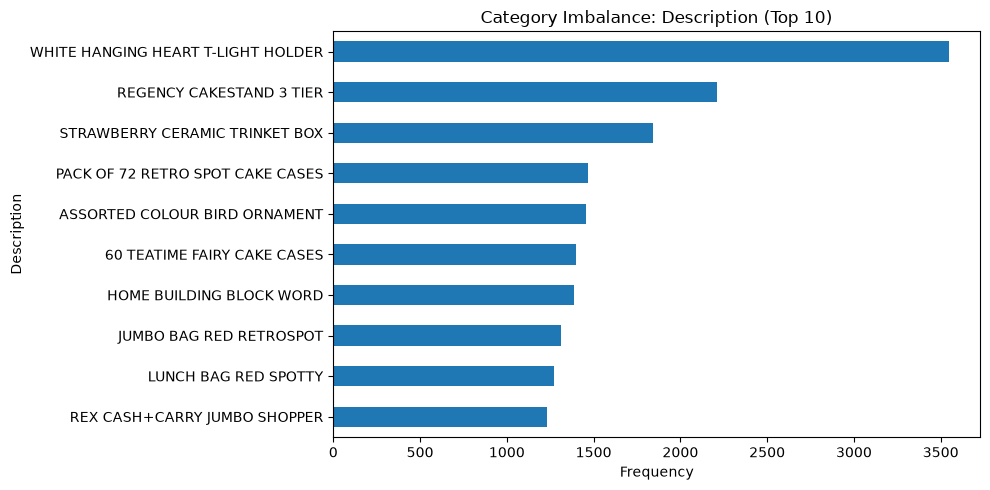


Category Imbalance Analysis: StockCode
Total non-missing records: 525461
Number of unique categories: 4632

Top 10 categories:


,Frequency,Percentage (%)
StockCode,,
85123A,3516,0.67
22423,2221,0.42
85099B,2057,0.39
21212,1933,0.37
21232,1843,0.35
20725,1620,0.31
84879,1458,0.28
84991,1400,0.27
21754,1386,0.26



Bottom 10 categories:


,Frequency,Percentage (%)
StockCode,,
90135,1,0.0
90136,1,0.0
90142D,1,0.0
84596g,1,0.0
90182A,1,0.0
85049g,1,0.0
72803b,1,0.0
79151B,1,0.0
22933,1,0.0


Most frequent category count: 3516
Least frequent category count: 1
Most-to-least frequency ratio: 3516.0


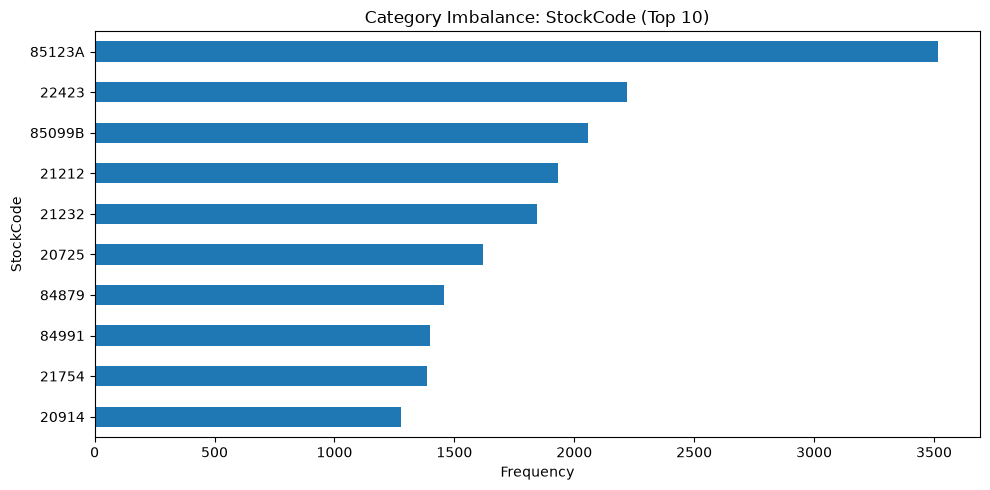

In [8]:

categorical_columns = ["Country", "Description", "StockCode"]

for column in categorical_columns:
    if column not in df.columns:
        print(f"\nColumn '{column}' is not available in the dataset.")
        continue

    counts = df[column].value_counts()
    percentages = df[column].value_counts(normalize=True) * 100

    imbalance_table = pd.DataFrame({
        "Frequency": counts,
        "Percentage (%)": percentages.round(2)
    })

    print(f"\n{'=' * 50}")
    print(f"Category Imbalance Analysis: {column}")
    print(f"{'=' * 50}")

    print("Total non-missing records:", df[column].count())
    print("Number of unique categories:", df[column].nunique())

    print("\nTop 10 categories:")
    display(imbalance_table.head(10))

    print("\nBottom 10 categories:")
    display(imbalance_table.tail(10).sort_values("Frequency"))

    # Compare the most frequent and least frequent categories
    if len(counts) >= 2:
        most_frequent = counts.iloc[0]
        least_frequent = counts.iloc[-1]

        print(f"Most frequent category count: {most_frequent}")
        print(f"Least frequent category count: {least_frequent}")

        if least_frequent > 0:
            print(
                "Most-to-least frequency ratio:",
                round(most_frequent / least_frequent, 2)
            )

    # Visualize the top 10 categories
    plot_data = counts.head(10).sort_values()

    plt.figure(figsize=(10, 5))
    plot_data.plot(kind="barh")
    plt.title(f"Category Imbalance: {column} (Top 10)")
    plt.xlabel("Frequency")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code examines the distribution of `Country`, `Description`, and `StockCode`.

It:
- Calculates the frequency and percentage of each category.
- Displays the 10 most frequent categories.
- Displays the 10 least frequent categories.
- Compares the most frequent and least frequent category counts.
- Plots the top 10 categories for visual comparison.

### 2. Why These Methods Were Used

- **`value_counts()`** calculates the frequency of each category.
- **`value_counts(normalize=True)`** calculates category proportions.
- **`head(10)`** selects the most frequent categories.
- **`tail(10)`** selects the least frequent categories from the frequency-sorted result.
- **`sort_values()`** arranges the least frequent categories for easier reading.
- **Frequency ratio** compares the most frequent category count with the least frequent count.
- **Horizontal bar chart** makes category frequencies easier to compare.

### 3. What the Output Means

- **Top 10 categories:** Shows which categories dominate the data.
- **Bottom 10 categories:** Shows the least frequent categories.
- **Frequency ratio:** A larger ratio indicates a larger difference between the most and least frequent categories.
- **Percentage:** Shows the share of non-missing records represented by a category.

The ratio can be large when the least frequent category has very few observations. It is a descriptive measure, not a complete statistical test of imbalance.

### 4. Insights to Identify

After running the code, check:

- Whether a few categories dominate the records.
- Whether the least frequent categories have only a few observations.
- Whether the country distribution is strongly concentrated.
- Whether product descriptions and stock codes have many low-frequency values.
- Whether the observed imbalance is expected from the business context.

Do not assume that frequent categories necessarily generate the highest revenue or profit.

### 5. Impact on an ML Pipeline

- **Feature Preprocessing:** Imbalanced input categories may require thoughtful encoding or category grouping.
- **Classification Targets:** If the target classes are imbalanced, accuracy alone may be misleading.
- **Model Evaluation:** Precision, recall, F1-score, and confusion matrices can help assess minority-class performance.
- **Resampling:** Over-sampling or under-sampling may be considered for suitable classification tasks, using training data only.
- **Data Leakage Prevention:** Resampling and learned preprocessing must not use validation or test data.

### Conclusion

Category imbalance analysis identifies dominant and underrepresented categories. It helps describe categorical features and guides further investigation.

Feature imbalance and target-class imbalance are different. Select a target variable only when it matches the business or prediction objective.

# Topic 8: Categorical Features vs Target Variable

## Step 1: Understand the Concept

Categorical feature and target variable analysis examines how a numerical or categorical target varies across different categories.

For example, in a retail dataset, `Country` is a categorical feature, while `Price` and `Quantity` are numerical variables that can be compared across countries.

### Why Is It Important?

- Identifies differences between categories.
- Helps discover useful business patterns.
- Supports feature selection and feature engineering.
- Helps evaluate whether categorical features may be useful for prediction.
- Provides insights for further statistical analysis and machine learning.

## Step 2: Demonstrate the Concept

### Simple Example

Suppose a retail dataset contains these records:

| Country | Quantity | Price |
|---|---:|---:|
| France | 5 | 10 |
| France | 3 | 20 |
| Germany | 4 | 15 |
| Germany | 6 | 25 |

We can calculate the average quantity and average price for each country.

### Real-World Example

An online retailer can compare transaction quantities and item prices across countries to identify differences in its retail activity.

### Business Example

A business analyst can investigate whether some countries have different average transaction quantities or item prices.

### AI/ML Use Case

Categorical features may help predict a numerical target, such as quantity or price, when they contain useful information. Their usefulness should be evaluated with appropriate validation.

### Important Characteristics

- Group-wise averages summarize numerical values by category.
- Group sizes matter when interpreting averages.
- Differences between group averages do not prove that the category causes the difference.
- The target variable must match the actual business question.

Country-wise Target Candidate Analysis


,Record_Count,Average_Quantity,Median_Quantity,Average_Price,Median_Price
Country,,,,,
United Kingdom,485852,9.12,3.0,4.54,2.10
EIRE,9670,19.51,10.0,7.95,2.10
Germany,8129,13.18,10.0,3.68,1.95
France,5772,12.90,10.0,4.19,1.65
Netherlands,2769,65.66,24.0,3.31,1.65
Spain,1278,14.34,10.0,6.19,1.69
Switzerland,1187,18.58,12.0,4.41,1.95
Portugal,1101,10.79,8.0,3.71,2.10
Belgium,1054,11.37,10.0,6.86,1.95


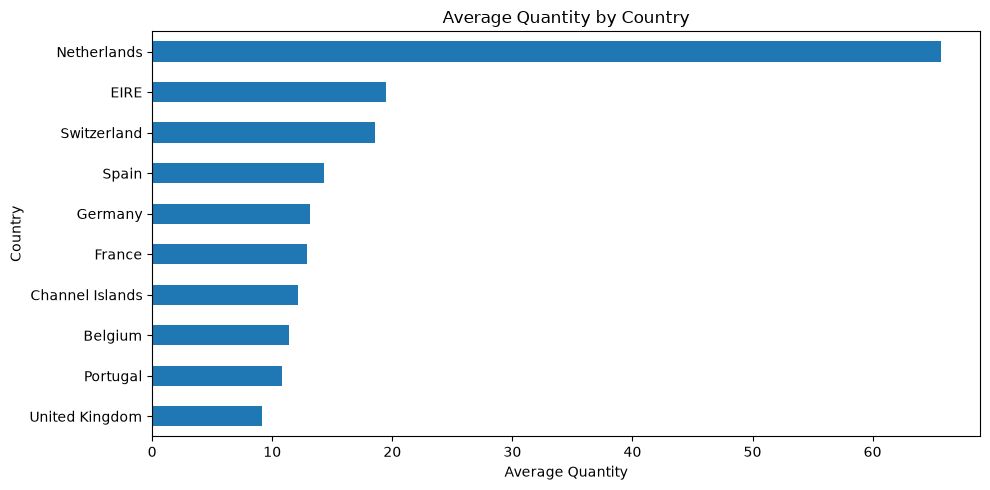

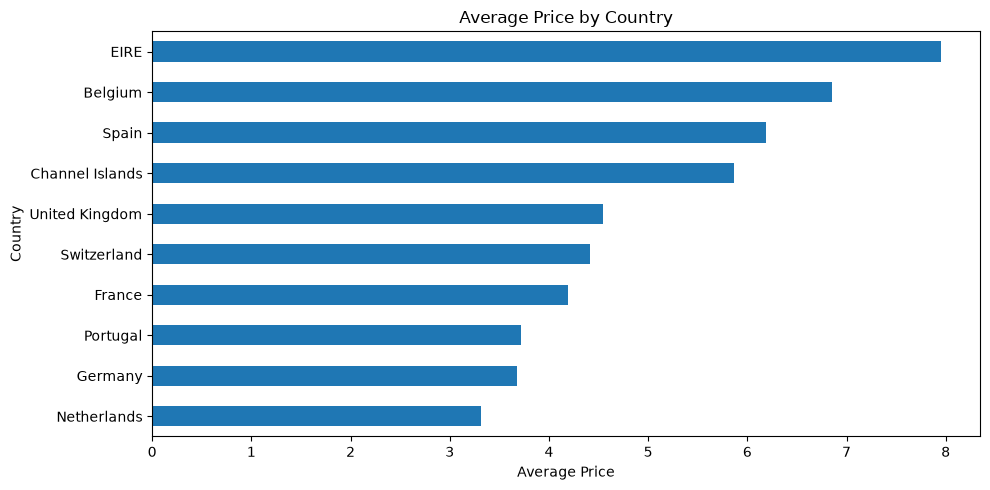

In [9]:

# Check that the required columns exist
required_columns = ["Country", "Quantity", "Price"]
missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    print("Required columns are missing:", missing_columns)
else:
    analysis_df = df[required_columns].copy()

    # Convert target candidates to numeric values
    for column in ["Quantity", "Price"]:
        analysis_df[column] = pd.to_numeric(
            analysis_df[column], errors="coerce"
        )

    # Remove records missing the grouping feature
    analysis_df = analysis_df.dropna(subset=["Country"])

    # Calculate group-wise summaries
    country_summary = (
        analysis_df.groupby("Country")
        .agg(
            Record_Count=("Country", "size"),
            Average_Quantity=("Quantity", "mean"),
            Median_Quantity=("Quantity", "median"),
            Average_Price=("Price", "mean"),
            Median_Price=("Price", "median")
        )
        .sort_values("Record_Count", ascending=False)
    )

    print("Country-wise Target Candidate Analysis")
    display(country_summary.head(10).round(2))

    # Visualize the 10 countries with the most records
    top_countries = country_summary.head(10).index
    plot_df = country_summary.loc[top_countries]

    plot_df["Average_Quantity"].sort_values().plot(
        kind="barh", figsize=(10, 5), title="Average Quantity by Country"
    )
    plt.xlabel("Average Quantity")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

    plot_df["Average_Price"].sort_values().plot(
        kind="barh", figsize=(10, 5), title="Average Price by Country"
    )
    plt.xlabel("Average Price")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()


## Step 3: Code Explanation and Analysis

### 1. What the Code Does

The code compares `Quantity` and `Price` across different countries.

It:
- Selects the required columns.
- Converts `Quantity` and `Price` to numeric values.
- Removes records with missing country values.
- Calculates record counts, means, and medians for each country.
- Displays summaries for the 10 countries with the most records.
- Creates bar charts comparing average quantity and average price.

### 2. Why These Methods Were Used

- **`pd.to_numeric()`** converts numerical columns and marks invalid values as missing.
- **`dropna(subset=["Country"])`** excludes records without a category for grouping.
- **`groupby("Country")`** groups records by country.
- **`agg()`** calculates multiple summary statistics in one operation.
- **`sort_values()`** ranks countries by record count.
- **Bar charts** make group-wise average comparisons easier to interpret.

### 3. What the Output Means

- **Record Count:** Number of records available for each country.
- **Average Quantity:** Mean quantity per transaction record for that country.
- **Median Quantity:** Middle quantity value for that country.
- **Average Price:** Mean item price per record for that country.
- **Median Price:** Middle item price for that country.

These measures summarize the available records; they do not directly measure total sales revenue or profitability.

### 4. Insights to Identify

After running the code, examine:

- Which countries have the largest numbers of records.
- Whether average quantity differs across countries.
- Whether average price differs across countries.
- Whether the mean and median differ substantially.
- Whether small group sizes make some country averages less reliable.

Write your findings based on the actual output rather than assuming which country has the highest value.

### 5. Impact on an ML Pipeline

- **Feature Selection:** Country may be useful if it provides predictive information.
- **Encoding:** Country can be encoded using an appropriate categorical encoding strategy.
- **Target Analysis:** Group-wise summaries help explore potential relationships before modelling.
- **Validation:** Evaluate the feature's predictive value on held-out data.
- **Data Leakage Prevention:** Fit preprocessing and any learned category mappings using training data only.

### Conclusion

Categorical feature versus target analysis helps identify differences in numerical outcomes across categories. These findings support business interpretation and guide feature selection for machine learning.

In this example, `Quantity` and `Price` are target candidates for exploratory comparison, not automatically the final prediction targets. The final target should be selected according to the actual prediction objective.